In [15]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, probplot
print(os.getcwd())
print(os.listdir())

c:\Users\migue\OneDrive - WeFind4U - Vargas Borges e Gonçalves, Lda\Ambiente de Trabalho\IRONHACK\LAB\lab-eda-bivariate
['.git', 'amazon_uk_products.csv.csv', 'lab-eda-bivariate_VSCO.ipynb', 'README.md']


In [17]:
df = pd.read_csv("amazon_uk_products.csv")


In [18]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [19]:
best_seller_prop = (
    crosstab
    .div(crosstab.sum(axis=1), axis=0)
    .sort_values(by=True, ascending=False)
)

best_seller_prop.head(10)


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


In [20]:
chi2, p, dof, expected = chi2_contingency(crosstab)

chi2, p


(np.float64(36540.20270061387), np.float64(0.0))

In [21]:
n = crosstab.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

cramers_v


np.float64(0.1222829439760564)

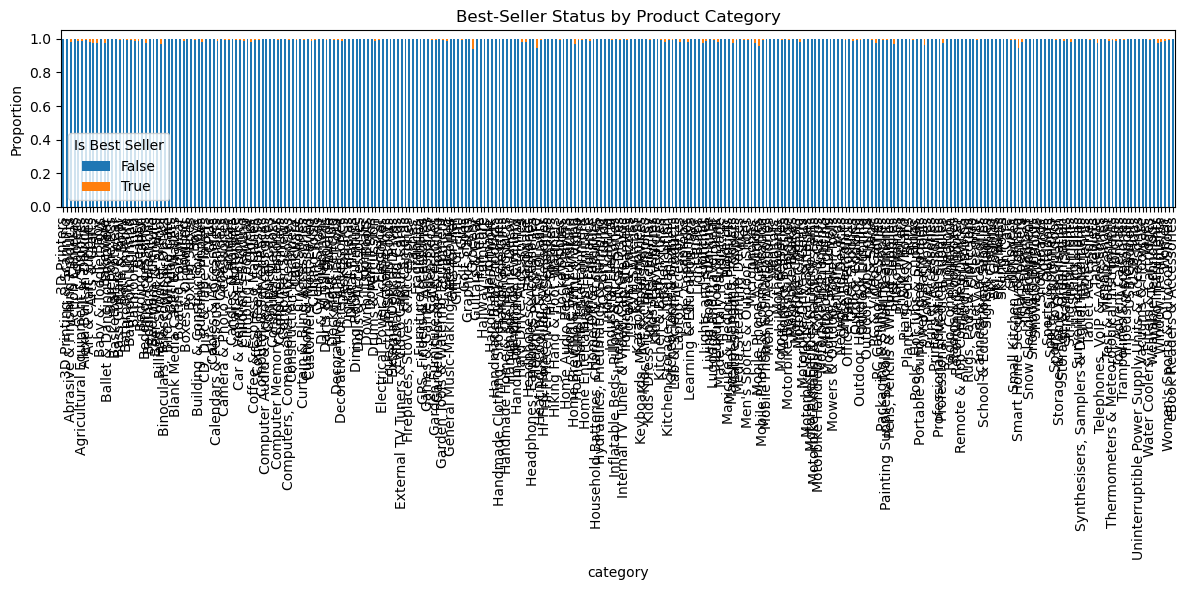

In [22]:
crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)

crosstab_norm.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.ylabel("Proportion")
plt.title("Best-Seller Status by Product Category")
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()


In [23]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower) & (df["price"] <= upper)]


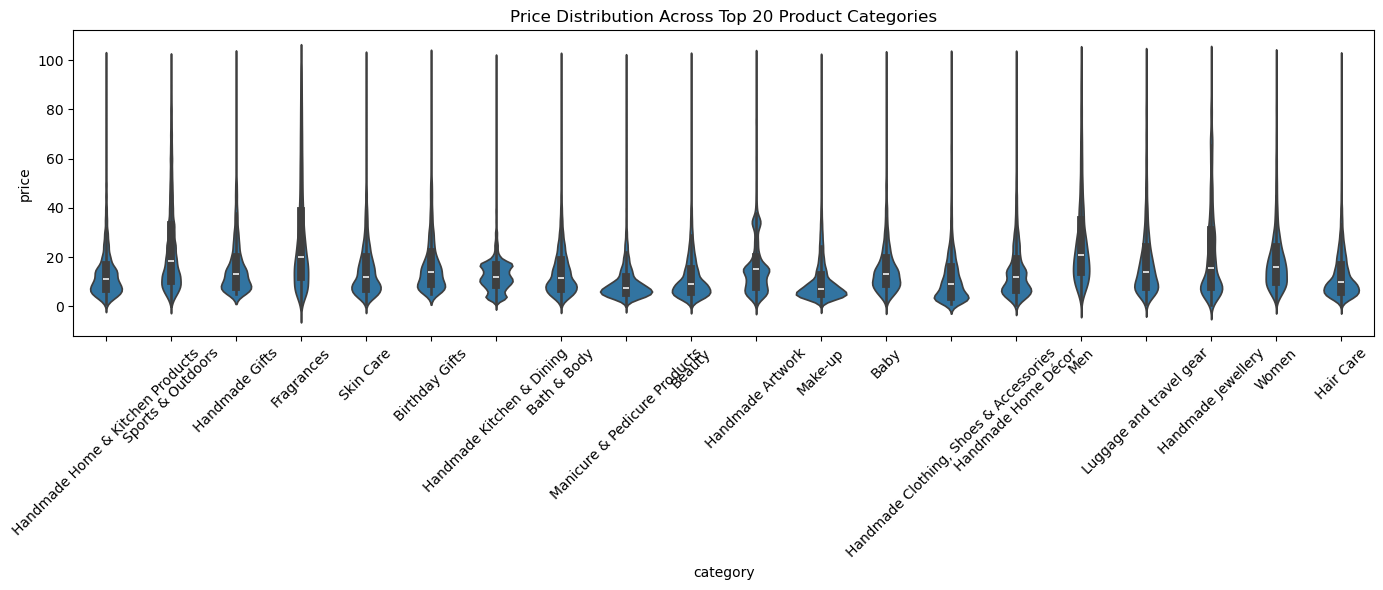

In [24]:
top_20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

plt.figure(figsize=(14,6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top_20_categories)],
    x="category",
    y="price"
)

plt.xticks(rotation=45)
plt.title("Price Distribution Across Top 20 Product Categories")
plt.tight_layout()
plt.show()


In [25]:
df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False).head()


category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

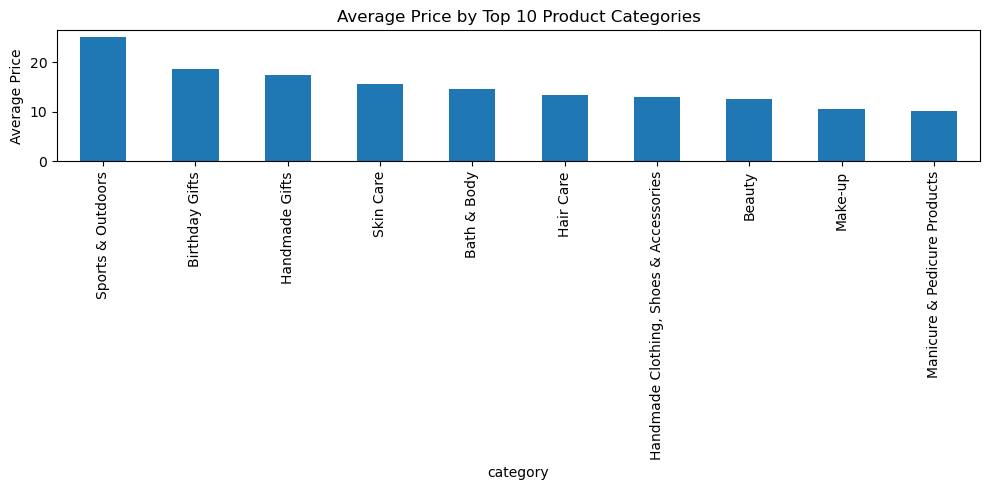

In [26]:
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price = (
    df_no_outliers[df_no_outliers["category"].isin(top_10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price.plot(kind="bar", figsize=(10,5))
plt.ylabel("Average Price")
plt.title("Average Price by Top 10 Product Categories")
plt.tight_layout()
plt.show()


In [27]:
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False).head()


category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

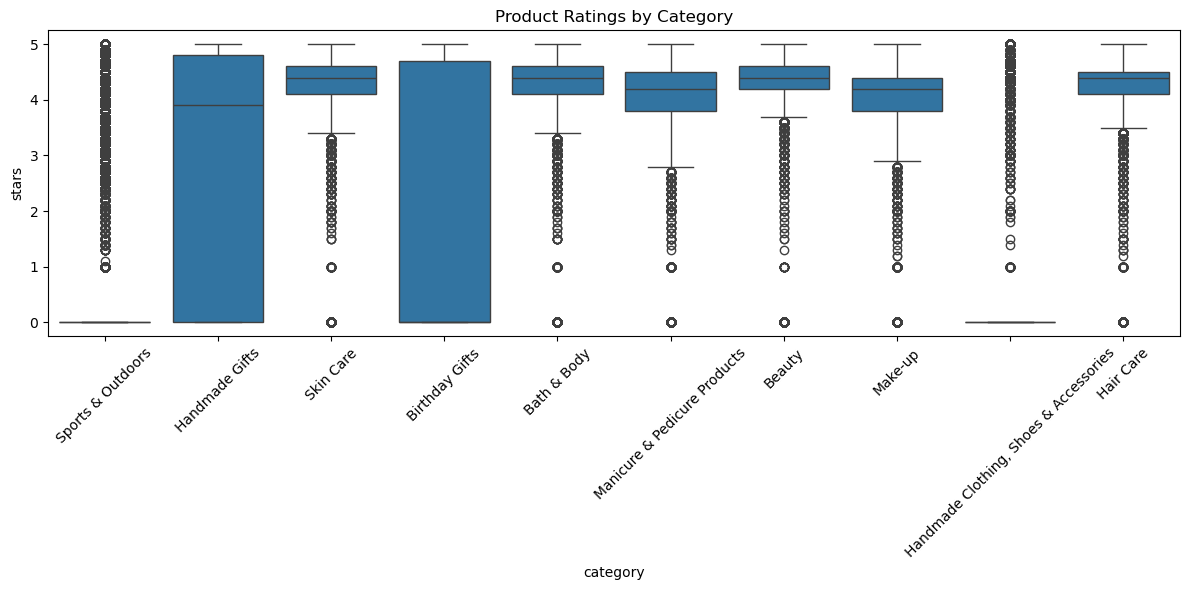

In [28]:
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top_10_categories)],
    x="category",
    y="stars"
)

plt.xticks(rotation=45)
plt.title("Product Ratings by Category")
plt.tight_layout()
plt.show()


In [29]:
df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False).head()


category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [30]:
corr, p_value = pearsonr(df_no_outliers["price"], df_no_outliers["stars"])

corr, p_value


(np.float64(-0.07767299878181355), np.float64(0.0))

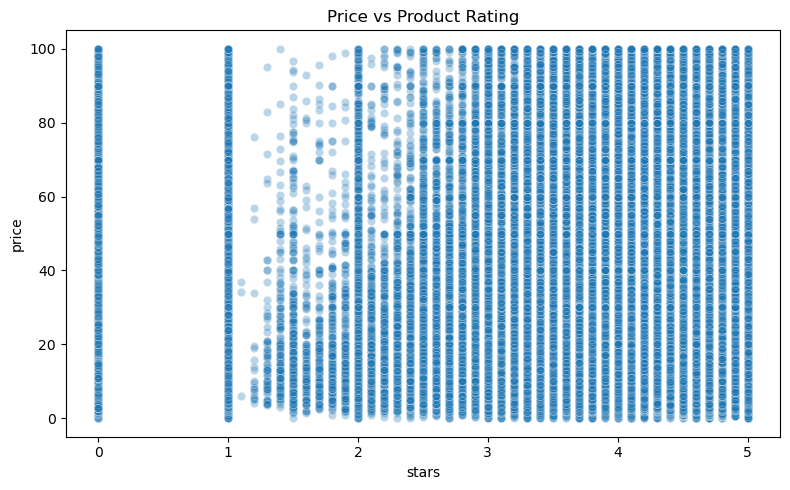

In [31]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df_no_outliers,
    x="stars",
    y="price",
    alpha=0.3
)

plt.title("Price vs Product Rating")
plt.tight_layout()
plt.show()


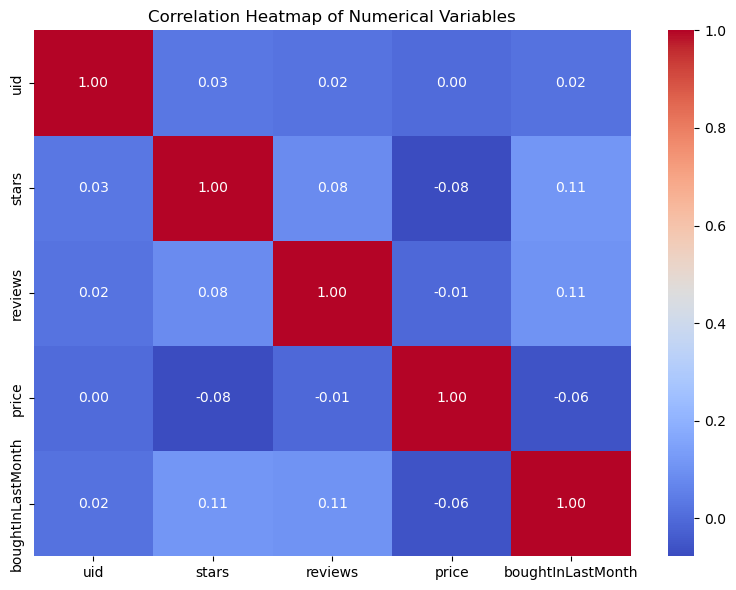

In [32]:
numerical_cols = df_no_outliers.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))
sns.heatmap(
    numerical_cols.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


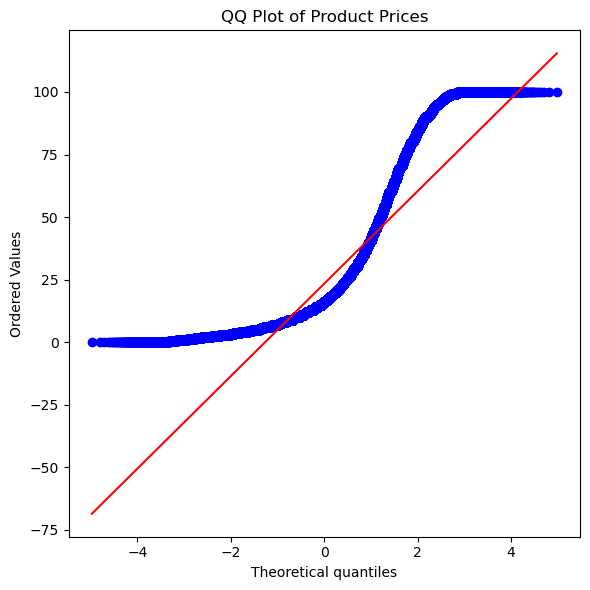

In [33]:
plt.figure(figsize=(6,6))
probplot(df_no_outliers["price"], plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()
